# Example: Pricing an American Put by Monte Carlo (Longstaff–Schwartz)
Previously, we priced American contracts on a lattice. In the lecture, we priced them by simulation, using the Longstaff–Schwartz regression to decide when to exercise. Does the simulation agree with the lattice, and how large is the early-exercise premium?

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Work the Longstaff–Schwartz method by hand:__ Reproduce the eight-path example from the original paper one backward step at a time. Check the result against the paper and the package.
> * __Compute American put premiums using Monte Carlo simulation:__ Price an American put on simulated risk-neutral share price paths. Compare the result with the CRR lattice and with the European premium on the same paths.
> * __Analyze the early-exercise premium across strike prices:__ Measure how much the right to exercise early adds as the strike price changes. Relate the result to when exercising a put early pays.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, and loads the functions in the local `src` directory. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file
using Random # seeded random numbers, so the Monte Carlo tables below reproduce

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

___

## Task 1: Work the Longstaff–Schwartz Example by Hand
In this task, we'll reproduce the eight-path example that Longstaff and Schwartz use to introduce their method, one backward step at a time.

__Reference:__
* [Longstaff, F. A.; Schwartz, E. S. (2001). "Valuing American Options by Simulation: A Simple Least-Squares Approach". The Review of Financial Studies. 14 (1): 113–147](https://doi.org/10.1093/rfs/14.1.113)

__Parameters:__ We have an American put with a strike price of $K$ = 1.10 USD/share on a share whose price today is $S(0)$ = 1.00 USD/share. The holder can exercise today or at $t$ = 1, 2, or 3 years. The __continuously compounded__ risk-free rate is $g_{y}$ = 6% per year, so one step back in time multiplies a cash flow by $\mathcal{D}^{-1}_{t+1,t}(g_{y}) = e^{-0.06}\approx 0.9418$.

Let's enter the eight simulated share price paths from the paper in the `S::Array{Float64,2}` matrix, one path per row and one date per column, and display them in a [`DataFrame`](https://dataframes.juliadata.org/stable/lib/types/#DataFrames.DataFrame) with [the `pretty_table(...)` function](https://ronisbr.github.io/PrettyTables.jl/stable/lib/library/#PrettyTables.pretty_table):

In [2]:
S = [
    1.00 1.09 1.08 1.34; # path 1
    1.00 1.16 1.26 1.54; # path 2
    1.00 1.22 1.07 1.03; # path 3
    1.00 0.93 0.97 0.92; # path 4
    1.00 1.11 1.56 1.52; # path 5
    1.00 0.76 0.77 0.90; # path 6
    1.00 0.92 0.84 1.01; # path 7
    1.00 0.88 1.22 1.34; # path 8
]; # share price (USD/share): rows are paths, columns are t = 0, 1, 2, 3
K = 1.10; # strike price (USD/share)
gᵧ = 0.06; # continuously compounded risk-free rate (1/year)
Δt = 1.0; # time between exercise dates (years)
𝒟(g,T) = exp(g*T); # accumulation factor from time 0 to time T, its inverse discounts
V(s) = max(K - s, 0.0); # put payoff V(K,s) (USD/share)

pretty_table(DataFrame(path = 1:8, t0 = S[:,1], t1 = S[:,2], t2 = S[:,3], t3 = S[:,4]);
    column_labels = ["path", "t = 0", "t = 1", "t = 2", "t = 3"],
    formatters = [fmt__printf("%.2f", [2, 3, 4, 5])],
    table_format = TextTableFormat(borders = text_table_borders__compact));

 ------ ------- ------- ------- -------
  path   t = 0   t = 1   t = 2   t = 3 
 ------ ------- ------- ------- -------
     1    1.00    1.09    1.08    1.34
     2    1.00    1.16    1.26    1.54
     3    1.00    1.22    1.07    1.03
     4    1.00    0.93    0.97    0.92
     5    1.00    1.11    1.56    1.52
     6    1.00    0.76    0.77    0.90
     7    1.00    0.92    0.84    1.01
     8    1.00    0.88    1.22    1.34
 ------ ------- ------- ------- -------


At expiration, the holder exercises every path that ends in the money, so each path's cash flow at $t=3$ is the put payoff $V(K,S(3)) = \max(K-S(3),0)$. We store the cash flows $Y_{i}(3)$ in the `cash_flow::Array{Float64,1}` variable:

In [3]:
cash_flow = V.(S[:,end]); # cash flow of each path, seen from t = 3 (USD/share)

pretty_table(DataFrame(path = 1:8, S₃ = S[:,end], cash_flow = cash_flow);
    column_labels = ["path", "S(3) (USD/share)", "cash flow (USD/share)"],
    formatters = [fmt__printf("%.2f", [2, 3])],
    table_format = TextTableFormat(borders = text_table_borders__compact));

 ------ ------------------ -----------------------
  path   S(3) (USD/share)   cash flow (USD/share) 
 ------ ------------------ -----------------------
     1               1.34                    0.00
     2               1.54                    0.00
     3               1.03                    0.07
     4               0.92                    0.18
     5               1.52                    0.00
     6               0.90                    0.20
     7               1.01                    0.09
     8               1.34                    0.00
 ------ ------------------ -----------------------


Now we work backward. At each earlier date $t$, the holder on an in-the-money path compares exercising now with holding. One backward step has three parts:
* __Discount:__ A cash flow the path receives later is worth $\mathcal{D}^{-1}_{t+1,t}(g_{y})$ times as much one date earlier. We store the discounted cash flows of the in-the-money paths in `Y`.
* __Regress:__ On the in-the-money paths only, we regress `Y` on the share price $X = S_{i}(t)$ with the basis $1, X, X^{2}$. The fit $\hat{C}_{t}(X) = \beta_{0} + \beta_{1}X + \beta_{2}X^{2}$ estimates the continuation value, the value of holding.
* __Decide:__ A path exercises when its payoff now, $V(K,X)$, is larger than $\hat{C}_{t}(X)$. Exercising replaces the path's later cash flow with the payoff now.

[The `backward_step!(...)` function](src/Helper.jl) takes one step, so we can apply it at $t=2$ and then at $t=1$. Inside it, [the `\` operator](https://docs.julialang.org/en/v1/stdlib/LinearAlgebra/#Base.:%5C%5C-Tuple{AbstractMatrix,%20AbstractVecOrMat}) solves the least-squares problem for the coefficients. The `!` in its name means it changes `cash_flow` in place.

Let's apply the step at $t=2$. Paths 1, 3, 4, 6, and 7 are in the money, and the paper's fit is $\hat{C}_{2}(X) = -1.070 + 2.983X - 1.813X^{2}$. We store the fitted coefficients in the `β_step2::Array{Float64,1}` variable and the step's table in the `step_2::DataFrame` variable:

In [4]:
β_step2, step_2 = backward_step!(cash_flow, S, 2; K = K, gᵧ = gᵧ, Δt = Δt);

pretty_table(step_2; column_labels = ["path", "X = S(2)", "Y", "Ĉ(X)", "V(K,X)", "decision"],
    formatters = [fmt__printf("%.2f", [2, 5]), fmt__printf("%.4f", [3, 4])],
    table_format = TextTableFormat(borders = text_table_borders__compact));

 ------ ---------- -------- -------- -------- ----------
  path   X = S(2)        Y     Ĉ(X)   V(K,X)   decision 
 ------ ---------- -------- -------- -------- ----------
     1       1.08   0.0000   0.0367     0.02       hold
     3       1.07   0.0659   0.0459     0.03       hold
     4       0.97   0.1695   0.1175     0.13   exercise
     6       0.77   0.1884   0.1520     0.33   exercise
     7       0.84   0.0848   0.1564     0.26   exercise
 ------ ---------- -------- -------- -------- ----------


Paths 4, 6, and 7 pay more now than the regression expects them to pay by holding, so they exercise at $t=2$. Let's repeat the step at $t=1$, where paths 1, 4, 6, 7, and 8 are in the money and the paper's fit is $\hat{C}_{1}(X) = 2.038 - 3.335X + 1.356X^{2}$. We store the fitted coefficients in the `β_step1::Array{Float64,1}` variable and the step's table in the `step_1::DataFrame` variable:

In [5]:
β_step1, step_1 = backward_step!(cash_flow, S, 1; K = K, gᵧ = gᵧ, Δt = Δt);

pretty_table(step_1; column_labels = ["path", "X = S(1)", "Y", "Ĉ(X)", "V(K,X)", "decision"],
    formatters = [fmt__printf("%.2f", [2, 5]), fmt__printf("%.4f", [3, 4])],
    table_format = TextTableFormat(borders = text_table_borders__compact));

 ------ ---------- -------- -------- -------- ----------
  path   X = S(1)        Y     Ĉ(X)   V(K,X)   decision 
 ------ ---------- -------- -------- -------- ----------
     1       1.09   0.0000   0.0135     0.01       hold
     4       0.93   0.1224   0.1087     0.17   exercise
     6       0.76   0.3108   0.2861     0.34   exercise
     7       0.92   0.2449   0.1170     0.18   exercise
     8       0.88   0.0000   0.1528     0.22   exercise
 ------ ---------- -------- -------- -------- ----------


Finally, we discount the cash flows to today and average over the eight paths with [the `mean(...)` function](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.mean). Exercising today pays $V(K,S(0))$ = 0.10 USD/share, so the holder keeps the contract when the average is larger.

Let's compare the hand calculation with [the `premium(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.premium), which runs the same steps on [a `MyLongstaffSchwartzContractPricingModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyLongstaffSchwartzContractPricingModel). We build the put with [the `build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanPutContractModel},%20NamedTuple}). Passing a `choice` function that always holds gives the European premium on the same paths. We check the results against the paper with [the `@assert` macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert) and [the `isapprox(...)` function](https://docs.julialang.org/en/v1/base/math/#Base.isapprox):

In [6]:
let

    # premium by hand: discount the date-1 cash flows to today, average, and compare with exercising today -
    by_hand = max(V(S[1,1]), (1/𝒟(gᵧ,Δt))*mean(cash_flow));

    # package: the American rule, and the European rule that always holds -
    put_contract_model = build(MyAmericanPutContractModel, (K = K, sense = 1));
    lsm_model = build(MyLongstaffSchwartzContractPricingModel, (S = S, r̄ = gᵧ, Δt = Δt));
    american = premium(put_contract_model, lsm_model);
    european = premium(put_contract_model, lsm_model; choice = (intrinsic, continuation) -> continuation); # always hold: the European rule

    df = DataFrame(quantity = ["American, by hand", "American, premium(...)",
            "American, Longstaff and Schwartz (2001)", "European, same paths", "early-exercise premium"],
        value = round.([by_hand, american, 0.1144, european, american - european], digits = 4));
    pretty_table(df; column_labels = ["quantity", "value (USD/share)"], alignment = [:l, :r],
        formatters = [fmt__printf("%.4f", [2])], table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the hand calculation, the package, and the paper agree -
    @assert isapprox(β_step2, [-1.070, 2.983, -1.813]; atol = 1e-3) "t = 2 fit differs from the paper"
    @assert isapprox(β_step1, [2.038, -3.335, 1.356]; atol = 1e-3) "t = 1 fit differs from the paper"
    @assert isapprox(by_hand, 0.1144; atol = 5e-5) "the hand calculation differs from the paper"
    @assert isapprox(american, by_hand; atol = 1e-12) "the package differs from the hand calculation"
    @assert american > european "the American premium is not above the European premium"
end

 ----------------------------------------- -------------------
  quantity                                  value (USD/share) 
 ----------------------------------------- -------------------
  American, by hand                                    0.1144
  American, premium(...)                               0.1144
  American, Longstaff and Schwartz (2001)              0.1144
  European, same paths                                 0.0564
  early-exercise premium                               0.0581
 ----------------------------------------- -------------------


___

## Task 2: Price the American Put by Simulation
In this task, we'll price the American version of the European put we priced previously by simulation and compare the result with the CRR lattice.

__Parameters:__ We have an American put that expires in $T$ = 365 days with a strike price of $K$ = 60.0 USD/share. The current share price is $S(0)$ = 60.0 USD/share. Assume a __continuously compounded__ risk-free rate $g_{y}$ = 5% per year and an annualized volatility $\sigma$ = 10%. The holder can exercise today or at the end of any day.

We start by defining the problem parameters:

In [7]:
Random.seed!(5660); # fix the RNG so the Monte Carlo tables below reproduce

Δt = (1.0/365.0); # time step: 1 x day (in 365-day years)
Sₒ = 60.0; # initial share price (USD/share)
K = 60.0; # strike price (USD/share)
T = 365.0*Δt; # time to expiration (in years)
gᵧ = 0.05; # continuously compounded risk-free rate (1/year)
σ̄ = 0.10; # volatility σ (1/√year)

Next, we build [a `MyGeometricBrownianMotionEquityModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) with the risk-neutral drift $g_{y}$, and [a `MyAmericanPutContractModel` instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel) for the put, and store them in the `model::MyGeometricBrownianMotionEquityModel` and `put_contract_model::MyAmericanPutContractModel` variables. The `number_of_samples::Array{Int64,1}` array holds the path counts we try:

In [8]:
model = build(MyGeometricBrownianMotionEquityModel, (
        μ = gᵧ, σ = σ̄)); # risk-neutral drift: under ℚ the expected share price grows at gᵧ
put_contract_model = build(MyAmericanPutContractModel, (K = K, sense = 1)); # the American put, long (sense = 1)
number_of_samples = [1_000, 10_000, 50_000]; # numbers of simulated paths M to try

For each number of paths in the `number_of_samples` array, we price the put twice on the same paths:
* __Simulate:__ [The `sample(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyGeometricBrownianMotionEquityModel,%20NamedTuple}) returns one row per date and one column per path, with the time in the first column. The `MyLongstaffSchwartzContractPricingModel` type expects one path per row, so we drop the time column and transpose with [the `permutedims(...)` function](https://docs.julialang.org/en/v1/base/arrays/#Base.permutedims).
* __American premium:__ The `premium(...)` function runs the Longstaff–Schwartz backward steps over the 365 exercise dates.
* __European premium:__ As in Task 1, always holding gives the European premium on the same paths. We also record its standard error `SE`, computed with [the `std(...)` function](https://docs.julialang.org/en/v1/stdlib/Statistics/#Statistics.std).

We store the results in the `lsm_price_df::DataFrame` variable, and [the `select(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#DataFrames.select) keeps the columns we display. So what do we get?

In [9]:
lsm_price_df = let

    # initialize -
    lsm_price_df = DataFrame();
    hold = (intrinsic, continuation) -> continuation; # the European rule: always hold

    for n ∈ number_of_samples
        X = VLQuantitativeFinancePackage.sample(model, (T₁ = 0.0, T₂ = T, Δt = Δt, Sₒ = Sₒ), number_of_paths = n); # one row per date (Distributions also exports sample, so we name the package)
        paths = permutedims(X[:, 2:end]); # one path per row, one date per column
        lsm_model = build(MyLongstaffSchwartzContractPricingModel, (S = paths, r̄ = gᵧ, Δt = Δt));

        american = premium(put_contract_model, lsm_model); # Longstaff–Schwartz
        european = premium(put_contract_model, lsm_model; choice = hold); # same paths, always hold
        P̄ = (1/𝒟(gᵧ,T))*max.(K .- paths[:,end], 0.0); # discounted European payoffs
        SE = std(P̄)/sqrt(n); # standard error of the European estimate

        push!(lsm_price_df, (n = n, dates = size(paths, 2), american = american, european = european,
            SE = SE, early = american - european));
    end

    pretty_table(select(lsm_price_df, :n, :american, :european, :SE, :early);
        column_labels = ["paths M", "American (USD/share)", "European (USD/share)", "SE (USD/share)",
            "early-exercise (USD/share)"], formatters = [fmt__printf("%.4f", [2, 3, 4, 5])],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    lsm_price_df # return the table, so later cells can check it
end;

 --------- ---------------------- ---------------------- ---------------- ----------------------------
  paths M   American (USD/share)   European (USD/share)   SE (USD/share)   early-exercise (USD/share) 
 --------- ---------------------- ---------------------- ---------------- ----------------------------
     1000                 1.4550                 1.1017           0.0711                       0.3533
    10000                 1.4530                 1.1709           0.0230                       0.2821
    50000                 1.4543                 1.1526           0.0102                       0.3018
 --------- ---------------------- ---------------------- ---------------- ----------------------------


From row to row, the European premium moves by about one SE, and the early-exercise premium moves the opposite way. Next, we price the same American put on [a CRR lattice](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAdjacencyBasedCRREquityPriceTree) with one step per day. Always holding on the same lattice gives the European premium. We build the lattice with [the `build(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAdjacencyBasedCRREquityPriceTree},%20NamedTuple}) and fill in its share prices with [the `populate(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.populate-Tuple{MyAdjacencyBasedCRREquityPriceTree}):

In [10]:
let

    # simulation, from the largest number of paths -
    sim = lsm_price_df[end, :];

    # CRR lattice with one step per day -
    hold = (intrinsic, continuation) -> continuation; # the European rule: always hold
    tree = build(MyAdjacencyBasedCRREquityPriceTree, (μ = gᵧ, T = T, σ = σ̄)) |>
        x -> populate(x, Sₒ = Sₒ, h = 365);
    crr_american = premium(put_contract_model, tree; sigdigits = 6);
    crr_european = premium(put_contract_model, tree; choice = hold, sigdigits = 6);

    df = DataFrame(quantity = ["American, Longstaff–Schwartz (M = $(sim.n))",
            "American, CRR lattice (h = 365)", "European, Monte Carlo (same paths)",
            "European, CRR lattice (h = 365)",
            "early-exercise premium, simulation", "early-exercise premium, lattice"],
        value = round.([sim.american, crr_american, sim.european, crr_european,
            sim.american - sim.european, crr_american - crr_european], digits = 4));
    pretty_table(df; column_labels = ["quantity", "value (USD/share)"], alignment = [:l, :r],
        formatters = [fmt__printf("%.4f", [2])], table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the simulation agrees with the lattice -
    @assert sim.dates == 366 "the paths do not cover the 365 daily exercise dates"
    @assert abs(sim.american - crr_american) < 0.02 "simulation and lattice differ by 0.02 USD/share or more"
    @assert abs(sim.european - crr_european) < 3*sim.SE "European simulation is 3 SE or more from the lattice"
    @assert sim.american ≥ sim.european "simulated American premium below European"
    @assert crr_american ≥ crr_european "lattice American premium below European"
end

 ------------------------------------------ -------------------
  quantity                                   value (USD/share) 
 ------------------------------------------ -------------------
  American, Longstaff–Schwartz (M = 50000)              1.4543
  American, CRR lattice (h = 365)                       1.4625
  European, Monte Carlo (same paths)                    1.1526
  European, CRR lattice (h = 365)                       1.1578
  early-exercise premium, simulation                    0.3018
  early-exercise premium, lattice                       0.3047
 ------------------------------------------ -------------------


The simulation and the lattice agree to about a cent, and both put the early-exercise premium near 0.30 USD/share.

___

## Task 3: Early-Exercise Premium versus Moneyness
In this task, we explore how the American and European put premiums, and the gap between them, change with the moneyness $K/S(0)$, the strike price relative to the share price.

We simulate one set of 10,000 paths and price puts with strike prices from $K$ = 50 to $K$ = 70 USD/share, a moneyness from 0.83 to 1.17, all other parameters held constant. For each strike price, we compute the Longstaff–Schwartz American and European premiums on the same paths. We also compute the American and European premiums on the CRR lattice with one step per day. Every premium is in USD/share.

We store the results in the `df_strike_sweep::DataFrame` variable, and [the `filter(...)` function](https://dataframes.juliadata.org/stable/lib/functions/#Base.filter) picks the strikes near the money for the table. So what do we get?

In [11]:
df_strike_sweep = let

    # initialize: one set of paths, one lattice -
    hold = (intrinsic, continuation) -> continuation; # the European rule: always hold
    X = VLQuantitativeFinancePackage.sample(model, (T₁ = 0.0, T₂ = T, Δt = Δt, Sₒ = Sₒ), number_of_paths = 10_000);
    paths = permutedims(X[:, 2:end]); # one path per row, one date per column
    lsm_model = build(MyLongstaffSchwartzContractPricingModel, (S = paths, r̄ = gᵧ, Δt = Δt));
    tree = build(MyAdjacencyBasedCRREquityPriceTree, (μ = gᵧ, T = T, σ = σ̄)) |>
        x -> populate(x, Sₒ = Sₒ, h = 365);
    df_strike_sweep = DataFrame();

    # loop over strikes -
    for strike ∈ range(50.0, stop = 70.0, step = 1.0)

        american_put = build(MyAmericanPutContractModel, (K = strike, sense = 1));

        lsm_american = premium(american_put, lsm_model); # simulation, American rule
        lsm_european = premium(american_put, lsm_model; choice = hold); # simulation, same paths, always hold
        crr_american = premium(american_put, tree; sigdigits = 6); # lattice, American rule
        crr_european = premium(american_put, tree; choice = hold, sigdigits = 6); # lattice, always hold

        push!(df_strike_sweep, (strike = strike, lsm_american = lsm_american, crr_american = crr_american,
            lsm_european = lsm_european, crr_european = crr_european,
            early = lsm_american - lsm_european));
    end

    # show the strikes near the money (the plot below shows the full sweep) -
    near_money = filter(:strike => in([50.0, 55.0, 60.0, 65.0, 70.0]), df_strike_sweep);
    near_money.moneyness = near_money.strike ./ Sₒ; # moneyness K/S(0)
    pretty_table(select(near_money, :strike, :moneyness, :lsm_american, :crr_american, :lsm_european, :crr_european, :early);
        column_labels = ["K", "K/S(0)", "American, simulation", "American, lattice", "European, simulation",
            "European, lattice", "early-exercise"],
        formatters = [fmt__printf("%.1f", [1]), fmt__printf("%.3f", [2]), fmt__printf("%.4f", [3, 4, 5, 6, 7])],
        fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));

    # checks: the simulation tracks the lattice at every strike -
    gap = abs.(df_strike_sweep.lsm_american .- df_strike_sweep.crr_american);
    @assert all(gap .< 0.03) "simulation and lattice differ by 0.03 USD/share or more"
    @assert all(df_strike_sweep.crr_american .≥ df_strike_sweep.crr_european) "American below European"

    df_strike_sweep # return
end;

 ------ -------- ---------------------- ------------------- ---------------------- ------------------- ----------------
     K   K/S(0)   American, simulation   American, lattice   European, simulation   European, lattice   early-exercise 
 ------ -------- ---------------------- ------------------- ---------------------- ------------------- ----------------
  50.0    0.833                 0.0210              0.0200                 0.0182              0.0181           0.0028
  55.0    0.917                 0.2488              0.2545                 0.2117              0.2192           0.0371
  60.0    1.000                 1.4630              1.4625                 1.1334              1.1578           0.3295
  65.0    1.083                 5.0000              5.0000                 3.4547              3.4516           1.5453
  70.0    1.167                10.0000             10.0000                 7.0844              7.0708           2.9156
 ------ -------- ---------------------- -----

`Unhide` the code cell below to see how we plot the premiums and the early-exercise premium against the moneyness $K/S(0)$ with [the `plot(...)` function](https://docs.juliaplots.org/stable/api/#RecipesBase.plot), [the `scatter!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.scatter!-Tuple), and [the `vline!(...)` function](https://docs.juliaplots.org/stable/api/#Plots.vline!-Tuple). In both panels, the gray dashed line marks the at-the-money strike, $K = S(0)$ = 60 USD/share.

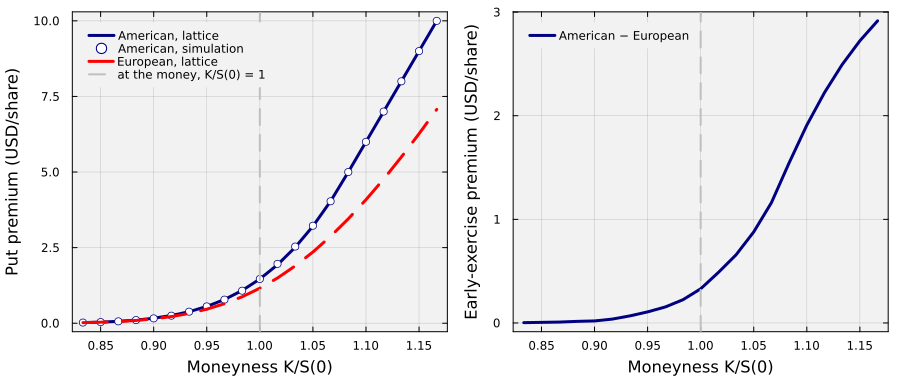

In [12]:
let
    df = df_strike_sweep;
    moneyness = df.strike ./ Sₒ; # moneyness K/S(0)

    # left: premiums versus the moneyness -
    p1 = plot(moneyness, df.crr_american, label = "American, lattice", lw = 3, c = :navy);
    scatter!(p1, moneyness, df.lsm_american, label = "American, simulation", ms = 4, c = :white, msc = :navy);
    plot!(p1, moneyness, df.crr_european, label = "European, lattice", lw = 3, c = :red, ls = :dash);
    vline!(p1, [1.0], lw = 2, c = :gray75, ls = :dash, label = "at the money, K/S(0) = 1");
    xlabel!(p1, "Moneyness K/S(0)");
    ylabel!(p1, "Put premium (USD/share)");

    # right: early-exercise premium versus the moneyness -
    p2 = plot(moneyness, df.early, label = "American − European", lw = 3, c = :navy);
    vline!(p2, [1.0], lw = 2, c = :gray75, ls = :dash, label = "");
    xlabel!(p2, "Moneyness K/S(0)");
    ylabel!(p2, "Early-exercise premium (USD/share)");

    plot(p1, p2, layout = (1, 2), size = (900, 380), left_margin = 4Plots.mm, bottom_margin = 4Plots.mm,
        bg = "gray95", background_color_outside = "white", framestyle = :box,
        fg_legend = :transparent, legend = :topleft);
end

### Discussion
1. Why does the early-exercise premium grow with $K/S(0)$?
2. Why is the American premium exactly $K - S(0)$ at $K/S(0)$ = 1.08 and 1.17?
3. Why is the European premium below $K - S(0)$ for these puts?

___

## Summary
In this example, we priced an American put by Monte Carlo simulation with the Longstaff–Schwartz method, first by hand on eight paths and then on simulated paths. We compared the simulation with the CRR lattice and measured the early-exercise premium across strike prices.

> __Key Takeaways:__
>
> * __Regression estimates the value of holding:__ At each exercise date, we regressed the discounted later cash flows of the in-the-money paths on the share price. A path exercises when its payoff now beats the fitted continuation value.
> * __Simulation and the lattice agree:__ On the same put, the Longstaff–Schwartz premium is within about a cent of the CRR premium. Always holding on the same paths gives the European premium, so one set of paths measures the early-exercise premium.
> * __The early-exercise premium grows as the put moves into the money:__ For low strike prices, the put rarely pays before expiration, and the two premiums nearly match. For high strike prices, the holder gains from receiving the strike early, and the American premium pulls away from the European one.

Both routes gave nearly the same American premium. To see how the early-exercise premium responds, change the volatility or the risk-free rate, and widen the tolerances in the checks.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___